# Домашнее задание: введение в статистику
Джафарова Фарида

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

alpha = 0.05

## Задача 1
$H_0: \mu = 120$ секунд, $H_1: \mu \ne 120$ секунд. Генеральное $\sigma$ известно, поэтому z-test, двусторонняя проверка.

In [2]:
mu0, n, x_mean, sigma = 120, 100, 124, 25

se = sigma / np.sqrt(n)
z = (x_mean - mu0) / se
p_value = 2 * stats.norm.sf(abs(z))
z_crit = stats.norm.ppf(1 - alpha / 2)

print(f'SE = {se}')
print(f'z = {z:.2f}, критическое значение = {z_crit:.2f}')
print(f'p-value = {p_value:.4f}')

SE = 2.5
z = 1.60, критическое значение = 1.96
p-value = 0.1096


Стандартная ошибка 2,5 секунды, оценка ушла от 120 на z = 1,6 стандартной ошибки. |z| = 1,6 < 1,96, p-value ≈ 0,11 > 0,05, поэтому оснований отвергать $H_0$ нет: отклонение в 4 секунды объясняется случайностью выборки.

## Задача 2
$H_0: \mu_2 - \mu_1 = 0$, $H_1: \mu_2 - \mu_1 \ne 0$. Дисперсии не считаем равными, поэтому интервал Уэлча.

In [3]:
n1, m1, s1 = 40, 50, 10
n2, m2, s2 = 40, 55, 10

diff = m2 - m1
se = np.sqrt(s1**2 / n1 + s2**2 / n2)
# степени свободы Уэлча–Саттертуэйта
df = (s1**2 / n1 + s2**2 / n2)**2 / ((s1**2 / n1)**2 / (n1 - 1) + (s2**2 / n2)**2 / (n2 - 1))
t_crit = stats.t.ppf(1 - alpha / 2, df)
ci_low, ci_high = diff - t_crit * se, diff + t_crit * se

print(f'разница средних = {diff}')
print(f'SE = {se:.4f}, df = {df:.1f}, t_крит = {t_crit:.4f}')
print(f'95% CI = [{ci_low:.3f}, {ci_high:.3f}]')

res = stats.ttest_ind_from_stats(m2, s2, n2, m1, s1, n1, equal_var=False)
print(f't = {res.statistic:.4f}, p-value = {res.pvalue:.4f}')

разница средних = 5
SE = 2.2361, df = 78.0, t_крит = 1.9908
95% CI = [0.548, 9.452]
t = 2.2361, p-value = 0.0282


Разница средних равна 5, 95% доверительный интервал ≈ [0,55; 9,45]. Ноль в интервал не попадает, поэтому $H_0$ об отсутствии разницы отвергается на уровне 5% (p-value ≈ 0,028). Самый маленький эффект, который ещё согласуется с данными, — нижняя граница интервала, около 0,55: гипотезы о разнице от 0,55 и выше данными не отвергаются.

## Задача 3
$H_0: p_1 = p_2$, $H_1: p_1 \ne p_2$. z-test для двух независимых долей.

In [4]:
x1, n1 = 90, 1000
x2, n2 = 120, 1000

p1, p2 = x1 / n1, x2 / n2
p = (x1 + x2) / (n1 + n2)
z = (p2 - p1) / np.sqrt(p * (1 - p) * (1 / n1 + 1 / n2))
p_value = 2 * stats.norm.sf(abs(z))

print(f'p1 = {p1:.3f}, p2 = {p2:.3f}, общая доля = {p:.3f}')
print(f'разница = {(p2 - p1) * 100:.1f} процентных пункта')
print(f'z = {z:.4f}, p-value = {p_value:.4f}')

p1 = 0.090, p2 = 0.120, общая доля = 0.105
разница = 3.0 процентных пункта
z = 2.1883, p-value = 0.0287


Конверсии 9% и 12%, разница 3 процентных пункта. z ≈ 2,19 > 1,96, p-value ≈ 0,029 < 0,05, поэтому $H_0$ о равенстве конверсий отвергаем: во второй группе конверсия в отклик выше.

## Задача 4
Стартовое число генератора: 7.

доля p-value < 0.05: 0.0570
среднее p-value: 0.512


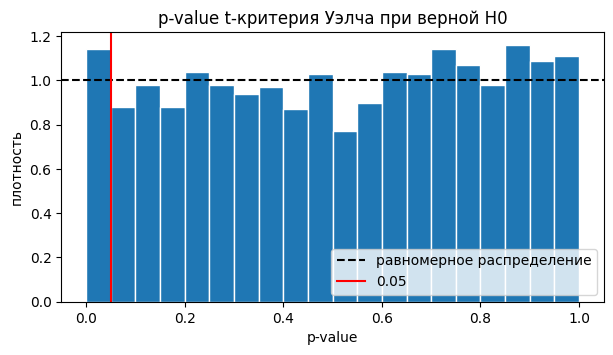

In [5]:
rng = np.random.default_rng(7)
n_sim, n = 2000, 200

p_values = np.empty(n_sim)
for i in range(n_sim):
    a = rng.normal(0, 1, n)
    b = rng.normal(0, 1, n)
    p_values[i] = stats.ttest_ind(b, a, equal_var=False).pvalue

print(f'доля p-value < 0.05: {np.mean(p_values < alpha):.4f}')
print(f'среднее p-value: {p_values.mean():.3f}')

plt.figure(figsize=(7, 3.5))
plt.hist(p_values, bins=20, range=(0, 1), density=True, edgecolor='white')
plt.axhline(1, color='black', linestyle='--', label='равномерное распределение')
plt.axvline(alpha, color='red', label='0.05')
plt.xlabel('p-value')
plt.ylabel('плотность')
plt.title('p-value t-критерия Уэлча при верной H0')
plt.legend(loc='lower right')
plt.show()

Распределение p-value близко к равномерному на отрезке от 0 до 1. Обе группы взяты из одного распределения, значит $H_0$ верна. Для непрерывной статистики p-value — это функция распределения статистики при $H_0$, применённая к самой статистике, поэтому $P(\text{p-value} \le x) = x$ для любого $x$ из [0, 1], а это и есть равномерное распределение. Поэтому доля p-value < 0,05 близка к α: получилось 5,7% (при 2000 повторах случайный разброс этой доли около ±1 процентного пункта). Это доля ошибок I рода.

## Задача 5
Стартовое число генератора: 7. Разница средних считается как «вторая минус первая», t Уэлча в том же направлении.

In [6]:
rng = np.random.default_rng(7)
n_sim, n = 1000, 60

diffs, t_stats, u_stats, p_t, p_u = (np.empty(n_sim) for _ in range(5))
for i in range(n_sim):
    a = rng.normal(0, 1, n)
    b = rng.normal(1, 1, n)
    b[:2] = -50
    diffs[i] = b.mean() - a.mean()
    t_res = stats.ttest_ind(b, a, equal_var=False)
    u_res = stats.mannwhitneyu(a, b, alternative='two-sided')  # U для первой группы
    t_stats[i], p_t[i] = t_res.statistic, t_res.pvalue
    u_stats[i], p_u[i] = u_res.statistic, u_res.pvalue

print(f'средняя разница средних: {diffs.mean():.3f}')
print(f'среднее t: {t_stats.mean():.3f}')
print(f'среднее U: {u_stats.mean():.1f}, при H0 ожидается {n * n / 2:.0f}')
print(f'медиана p-value Уэлча: {np.median(p_t):.4f}')
print(f'медиана p-value Манна–Уитни: {np.median(p_u):.2e}')
print(f'минимальное p-value Уэлча: {p_t.min():.3f}, максимальное p-value Манна–Уитни: {p_u.max():.4f}')
print(f'доля отвержений H0, Уэлч: {np.mean(p_t < alpha):.3f}')
print(f'доля отвержений H0, Манн–Уитни: {np.mean(p_u < alpha):.3f}')

средняя разница средних: -0.686
среднее t: -0.569
среднее U: 941.4, при H0 ожидается 1800
медиана p-value Уэлча: 0.5703
медиана p-value Манна–Уитни: 6.37e-06
минимальное p-value Уэлча: 0.325, максимальное p-value Манна–Уитни: 0.0292
доля отвержений H0, Уэлч: 0.000
доля отвержений H0, Манн–Уитни: 1.000


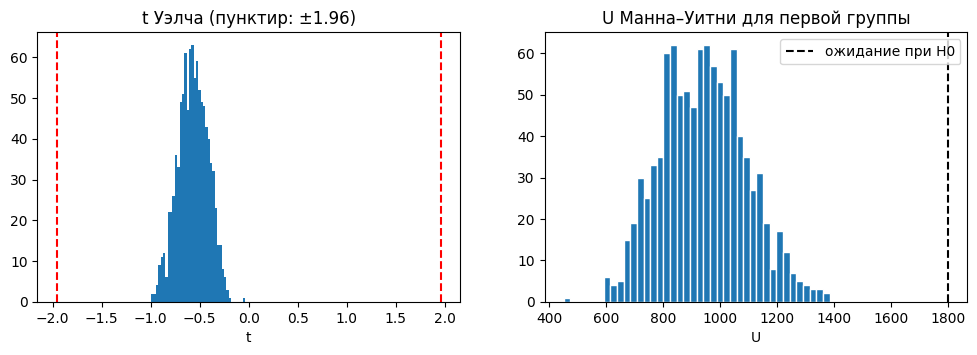

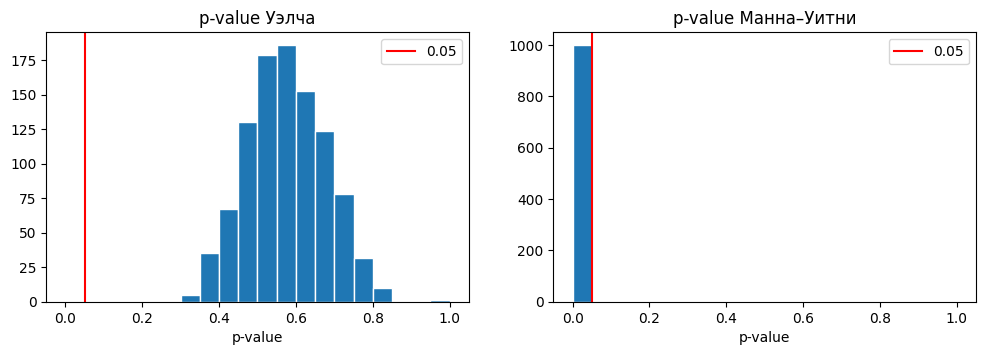

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(t_stats, bins=40)
for c in (-1.96, 1.96):
    ax[0].axvline(c, color='red', linestyle='--')
ax[0].set_title('t Уэлча (пунктир: ±1.96)')
ax[0].set_xlabel('t')

ax[1].hist(u_stats, bins=40, edgecolor='white')
ax[1].axvline(n * n / 2, color='black', linestyle='--', label='ожидание при H0')
ax[1].set_title('U Манна–Уитни для первой группы')
ax[1].set_xlabel('U')
ax[1].legend()
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(p_t, bins=20, range=(0, 1), edgecolor='white')
ax[0].axvline(alpha, color='red', label='0.05')
ax[0].set_title('p-value Уэлча')
ax[0].set_xlabel('p-value')
ax[0].legend()

ax[1].hist(p_u, bins=20, range=(0, 1), edgecolor='white')
ax[1].axvline(alpha, color='red', label='0.05')
ax[1].set_title('p-value Манна–Уитни')
ax[1].set_xlabel('p-value')
ax[1].legend()
plt.show()

Средняя разница средних ≈ −0,69, хотя истинный сдвиг +1: два значения −50 сдвигают среднее второй группы примерно на −1,7 и сильно увеличивают её дисперсию. Поэтому t Уэлча сосредоточен около −0,6, почти все значения внутри ±1,96, а p-value Уэлча сосредоточены примерно между 0,3 и 0,85 (медиана ≈ 0,57), ниже 0,05 нет ни одного.

U для первой группы в среднем ≈ 941 при ожидаемых 1800 при $H_0$: наблюдения первой группы обычно меньше наблюдений второй. p-value Манна–Уитни все сосредоточены у нуля (медиана порядка $10^{-6}$).

Решения: Уэлч не отвергает $H_0$ ни в одном из 1000 повторов, Манн–Уитни отвергает во всех. Выводы разошлись. t-критерий сравнивает средние, а среднее неустойчиво к выбросам: два наблюдения меняют знак разницы и в несколько раз увеличивают стандартную ошибку, поэтому t близок к нулю. Манн–Уитни работает с рангами: значение −50 получает наименьший ранг, его величина не важна, а остальные 58 наблюдений второй группы в основном больше наблюдений первой, поэтому сдвиг обнаруживается. При этом Манн–Уитни проверяет вероятность превосходства, а не равенство средних, и его результат нельзя читать как «среднее второй группы больше».

## Задача 6
Стартовое число генератора: 7. $H_0: \mu_2 - \mu_1 = 0$, $H_1: \mu_2 - \mu_1 \ne 0$.

In [8]:
rng = np.random.default_rng(7)
first = rng.normal(10, 2, 80)
second = rng.normal(10.8, 2.6, 75)

print(f'первая: n={first.size}, mean={first.mean():.3f}, s={first.std(ddof=1):.3f}')
print(f'вторая: n={second.size}, mean={second.mean():.3f}, s={second.std(ddof=1):.3f}')

res = stats.ttest_ind(second, first, equal_var=False)
ci = res.confidence_interval(confidence_level=0.95)
diff = second.mean() - first.mean()

print(f'разница средних (вторая минус первая) = {diff:.3f}')
print(f't = {res.statistic:.4f}, p-value = {res.pvalue:.4f}')
print(f'95% CI Уэлча = [{ci.low:.3f}, {ci.high:.3f}]')

первая: n=80, mean=9.647, s=1.781
вторая: n=75, mean=10.404, s=2.255
разница средних (вторая минус первая) = 0.757
t = 2.3081, p-value = 0.0225
95% CI Уэлча = [0.109, 1.404]


Разница средних 0,757, 95% доверительный интервал Уэлча [0,109; 1,404], t ≈ 2,31, p-value ≈ 0,022 < 0,05, поэтому $H_0$ отвергаем. Ноль в интервал не попадает. Самый маленький эффект, который ещё согласуется с данными, — около 0,11 (нижняя граница интервала). Интервал широкий: эффект может быть как 0,11, так и 1,4.

## Задача 7
Стартовое число генератора для бутстрапа: 7.

95% CI бутстрапа = [0.101, 1.389]
95% CI Уэлча     = [0.109, 1.404]
доля разниц <= 0: 0.0110
p-value Уэлча: 0.0225


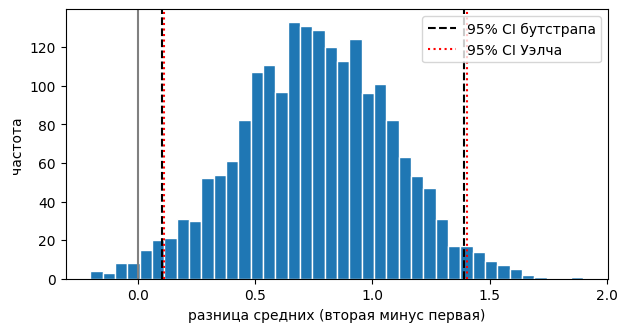

In [9]:
rng = np.random.default_rng(7)
n_boot = 2000

boot_diffs = np.empty(n_boot)
for i in range(n_boot):
    f = rng.choice(first, size=first.size, replace=True)
    s = rng.choice(second, size=second.size, replace=True)
    boot_diffs[i] = s.mean() - f.mean()

boot_low, boot_high = np.percentile(boot_diffs, [2.5, 97.5])
share_le_0 = np.mean(boot_diffs <= 0)

print(f'95% CI бутстрапа = [{boot_low:.3f}, {boot_high:.3f}]')
print(f'95% CI Уэлча     = [{ci.low:.3f}, {ci.high:.3f}]')
print(f'доля разниц <= 0: {share_le_0:.4f}')
print(f'p-value Уэлча: {res.pvalue:.4f}')

plt.figure(figsize=(7, 3.5))
plt.hist(boot_diffs, bins=40, edgecolor='white')
plt.axvline(boot_low, color='black', linestyle='--', label='95% CI бутстрапа')
plt.axvline(boot_high, color='black', linestyle='--')
plt.axvline(ci.low, color='red', linestyle=':', label='95% CI Уэлча')
plt.axvline(ci.high, color='red', linestyle=':')
plt.axvline(0, color='gray')
plt.xlabel('разница средних (вторая минус первая)')
plt.ylabel('частота')
plt.legend()
plt.show()

Распределение бутстрап-разниц близко к нормальному с центром около наблюдаемой разницы 0,757. 95% интервал бутстрапа [0,101; 1,389] почти совпадает с интервалом Уэлча [0,109; 1,404]: при размерах групп 75 и 80 разница средних по центральной предельной теореме распределена почти нормально, поэтому оба метода дают близкий результат. Доля повторных выборок с разницей не больше нуля — 1,1%.

In [10]:
# бутстрап при верной H0: сдвигаем обе группы к общему среднему
pooled_mean = np.concatenate([first, second]).mean()
first0 = first - first.mean() + pooled_mean
second0 = second - second.mean() + pooled_mean

boot_h0 = np.empty(n_boot)
for i in range(n_boot):
    f = rng.choice(first0, size=first.size, replace=True)
    s = rng.choice(second0, size=second.size, replace=True)
    boot_h0[i] = s.mean() - f.mean()

p_boot = np.mean(np.abs(boot_h0) >= abs(diff))
print(f'двусторонний p-value бутстрапа при H0: {p_boot:.4f}')
print(f'2 * доля разниц <= 0: {2 * share_le_0:.4f}')

двусторонний p-value бутстрапа при H0: 0.0190
2 * доля разниц <= 0: 0.0220


Назвать эту долю p-value нельзя. p-value считается при условии, что $H_0$ верна, а бутстрап-распределение построено по наблюдаемым данным и сосредоточено вокруг наблюдаемой разницы, а не вокруг нуля. Эта доля показывает, какая часть распределения оценки лежит по другую сторону от нуля, и связана с доверительным интервалом: ноль вне 95% интервала, если доля меньше 2,5%. Кроме того, она односторонняя.

Чтобы получить p-value бутстрапом, нужно сделать $H_0$ верной (сдвинуть обе группы к общему среднему) и посчитать долю разниц, по модулю не меньших наблюдаемой: получилось ≈ 0,019. Удвоенная доля (0,022) близка к нему и к p-value Уэлча (0,0225) только потому, что распределение почти симметричное и нормальное; в общем случае это лишь приближение.